<a href="https://colab.research.google.com/github/Meynard-Angelo-Javier/Data-Science-Projects/blob/main/Credit_Risk_Probability_of_Default_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Probability Default Model

In this project, we will know about building a Probability Default Model. The dataset we have are already cleaned, structured, and categorical variables are mostly numerically encoded. We can understand the relationship between variables and how they are correlated from one another before we move on model building. The following are our objectives for this project.
* Understand the target variable (default payment next month)
* Perform an Exploratory Data Analysis on data features. These include Demographic Characteristics of borrowers, credit limit balance, payment behaviors, and financial behaviors.
* Seperate the features and the target variable
* Build the model. We will try these models and know which is the best. (Logistic Regression, Decision Tree, Random Forest, and XGBoost)


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from scipy.stats import pointbiserialr
from scipy.stats import mannwhitneyu
from scipy.stats import ttest_ind
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.model_selection import train_test_split

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
path = "/content/drive/MyDrive/Machine Learning Models/Datasets/default of credit card clients.xls"

In [ ]:
pd_df = pd.read_excel(path)
pd_df.head()

,Unnamed: 0,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
0,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
1,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
2,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
3,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
4,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0


Before we move on. We must understand first the values of our dataset or dataframe 'pd_df'.
* **ID** - key identifier
* **LIMIT_BAL** - Amount of given credit (NT Dollars). This includes both the individual borrower credit and his/her family credit.
* **SEX** - Gender of the borrower. (1 = Male, 2 = Female)
* **EDUCATION** - Highest education obtained. (1 = Graduate School, 2 = University, 3 = High School, 4 = Others)
* **MARRIAGE** - Marital status of the borrower. (1 = Married, 2 = Single, 3 = Others)
* **AGE** - The age of the borrower.
* **PAY_0** to **PAY_6** - History of past payment monthly payment records from April to September 2005. (**PAY_0** - repayment status in September 2005, **PAY_2** - repayment status in August 2005, ..., **PAY_6** - repayment status of April 2005)
* **BILL_AMT1** to **BILL_AMT5** - Amount of bill statement (NT Dollars). (**BILL_AMT1** - Amount of bill statement on September 2005, **BILL_AMT2** - Amount of bill statement on August 2005, ..., **BILL_AMT5** - Amount of bill statement on April 2005)
* **PAY_AMT1** to **PAY_AMT5** - Amount of previous payment (NT Dollars). (**PAY_AMT1** - amount paid on September 2005, **PAY_AMT2** - amount paid on August 2005, ..., **PAY_AMT5** - amount paid on April 2005)
* **default payment next month** - The borrower will default next month. (Yes = 1, No = 0)

In [ ]:
headers = pd_df.iloc[0]
pd_df = pd.DataFrame(pd_df.values[1:], columns=headers)
pd_df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [ ]:
pd_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   ID                          30000 non-null  object
 1   LIMIT_BAL                   30000 non-null  object
 2   SEX                         30000 non-null  object
 3   EDUCATION                   30000 non-null  object
 4   MARRIAGE                    30000 non-null  object
 5   AGE                         30000 non-null  object
 6   PAY_0                       30000 non-null  object
 7   PAY_2                       30000 non-null  object
 8   PAY_3                       30000 non-null  object
 9   PAY_4                       30000 non-null  object
 10  PAY_5                       30000 non-null  object
 11  PAY_6                       30000 non-null  object
 12  BILL_AMT1                   30000 non-null  object
 13  BILL_AMT2                   30000 non-null  ob

Many of the columns has an object data type other than 'MARRIAGE' and 'EDUCATION'. However, after understanding the contents of the column, they need to be an integer data type not just 'MARRIAGE' and 'EDUCATION'.

In [ ]:
pd_df = pd_df.astype('int64')

In [ ]:
pd_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null  int64
 14  BILL_A

In [ ]:
pd_df.describe(include='all')

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
mean,15000.500000,167484.322667,1.603733,1.853133,1.551867,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,...,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200
std,8660.398374,129747.661567,0.489129,0.790349,0.521970,9.217904,1.123802,1.197186,1.196868,1.169139,...,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062
min,1.000000,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,...,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,7500.750000,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000
50%,15000.500000,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,...,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000
75%,22500.250000,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,...,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000
max,30000.000000,1000000.000000,2.000000,6.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,...,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000,1.000000


First, we understand our target variable.

In [ ]:
pd_df['default payment next month'].value_counts()

,count
default payment next month,
0,23364
1,6636


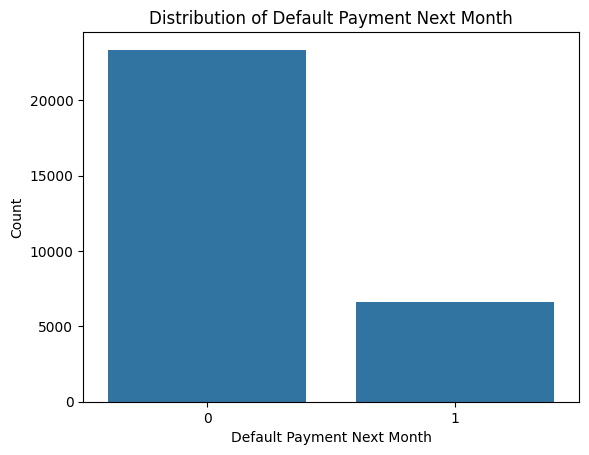

In [ ]:
sns.countplot(data=pd_df, x='default payment next month')
plt.title('Distribution of Default Payment Next Month')
plt.xlabel('Default Payment Next Month')
plt.ylabel('Count')
plt.show()

In [ ]:
default_rate = pd_df['default payment next month'].mean() * 100
print('The default rate is {:.2f} %.'.format(default_rate))

The default rate is 22.12 %.


Here we can see that the ratio of default to non-default are 1 to 5. Out of 5 people, 1 is expected to default. We move on to exploratory data analysis of features.

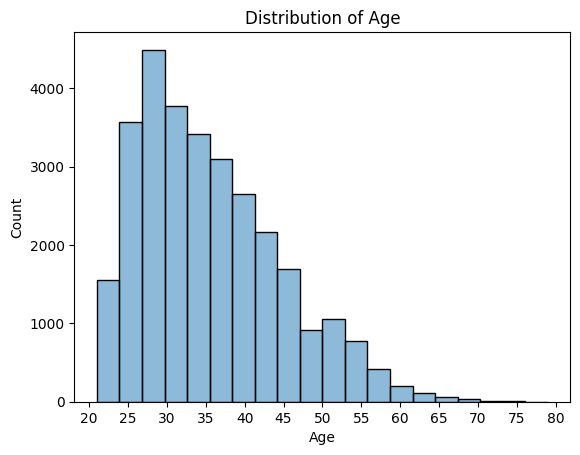

In [ ]:
#AGE
ticks = np.linspace(20, 80, 13)

sns.histplot(data=pd_df, x='AGE', bins=20, alpha=0.5)
plt.xticks(ticks)
plt.title('Distribution of Age')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

As we can see here, most of the borrower are between the age 25 to 35 years old. Being the most common are the near age of 30 years old. This made the distribution skewed.

SEX
2    18112
1    11888
Name: count, dtype: int64


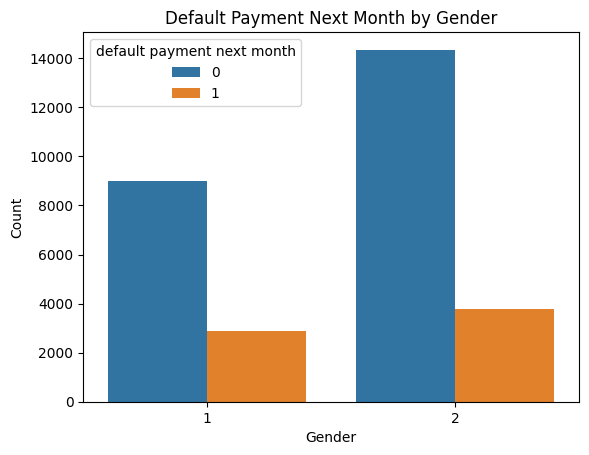

In [ ]:
#SEX
print(pd_df['SEX'].value_counts())

sns.countplot(data=pd_df, x='SEX', hue='default payment next month')
plt.title('Default Payment Next Month by Gender')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.show()

The distribution between the borrowers defaulting and non-defaulting are quite big. Showing that most of the borrowers are female but having almost the same default counts as the male. With this, we can assume that males are most likely to default that female.

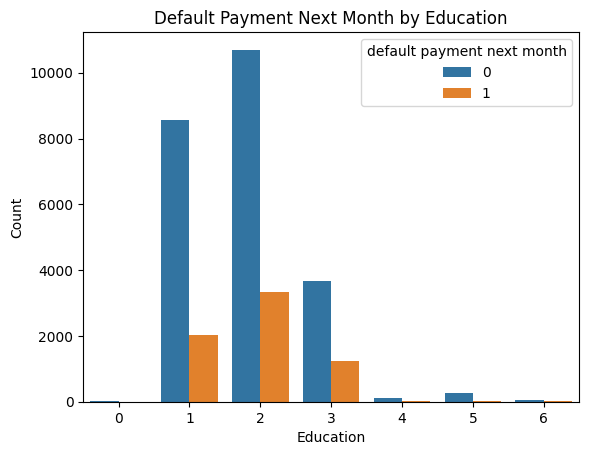

In [ ]:
#EDUCATION
sns.countplot(data=pd_df, x='EDUCATION', hue='default payment next month')
plt.title('Default Payment Next Month by Education')
plt.xlabel('Education')
plt.ylabel('Count')
plt.show()

In [ ]:
pd_df['EDUCATION'].value_counts()

,count
EDUCATION,
2,14030
1,10585
3,4917
5,280
4,123
6,51
0,14


As we can see here, most of the borrowers have an education of graduate school and university. This is the same for borrowers that defaulted. We can also observe that there are values that are not stated earlier such as 0, 5, and 6. We can assume that these values are in the 'Others' education category, so we will change these to '4'.

In [ ]:
pd_df['EDUCATION'] = pd_df['EDUCATION'].replace({0:4, 5:4,6:4})
pd_df['EDUCATION'].value_counts()

,count
EDUCATION,
2,14030
1,10585
3,4917
4,468


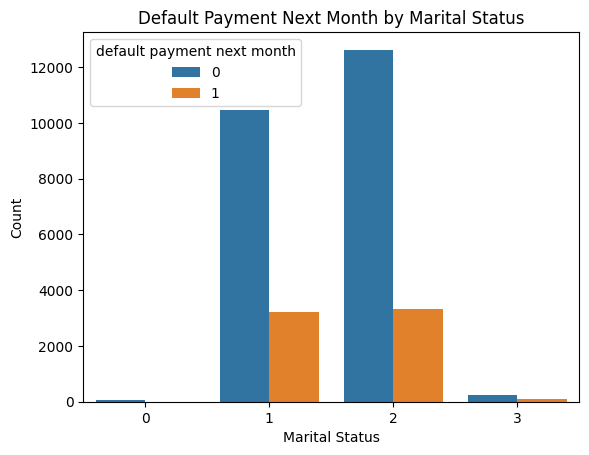

In [ ]:
#MARRIAGE
sns.countplot(data=pd_df, x='MARRIAGE', hue='default payment next month')
plt.title('Default Payment Next Month by Marital Status')
plt.xlabel('Marital Status')
plt.ylabel('Count')
plt.show()

For the column 'MARRIAGE', we can observe that the borrowers that are single have the highest count than married and others. Also similar to 'EDUCATION' column, there are other values than the those are stated in the beginning. We will do the same with and change this to '0'.

In [ ]:
pd_df['MARRIAGE'] = pd_df['MARRIAGE'].replace({0:3})

In [ ]:
pd_df['MARRIAGE'].value_counts()

,count
MARRIAGE,
2,15964
1,13659
3,377


Next, we will move on credit limit balance.

In [ ]:
pd_df['LIMIT_BAL'].describe()

,LIMIT_BAL
count,30000.000000
mean,167484.322667
std,129747.661567
min,10000.000000
25%,50000.000000
50%,140000.000000
75%,240000.000000
max,1000000.000000


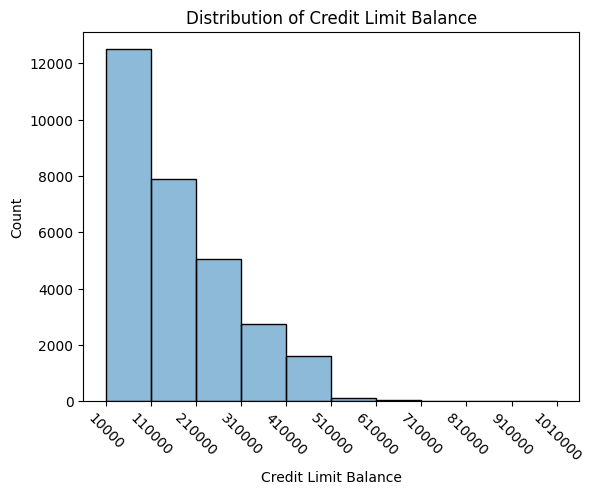

In [ ]:
bin_edges = np.linspace(pd_df['LIMIT_BAL'].min(), pd_df['LIMIT_BAL'].max() + 10000, 11)

sns.histplot(data=pd_df, x='LIMIT_BAL', bins=bin_edges, alpha=0.5)
plt.ticklabel_format(style='plain', axis='x')
plt.xticks(bin_edges, rotation=-45)
plt.title('Distribution of Credit Limit Balance')
plt.xlabel('Credit Limit Balance')
plt.ylabel('Count')
plt.show()

We can see here that most of the borrowers have a credit limit balance between 10000 to 110000. Being concentrated at lower credit limti balance.

In [ ]:
pd_df['LIMIT_BAL'].value_counts()

,count
LIMIT_BAL,
50000,3365
20000,1976
30000,1610
80000,1567
200000,1528
...,...
800000,2
1000000,1
327680,1


In [ ]:
pd_df['LIMIT_BAL'].max()

1000000

We can see this in detail that most of borrowers have a credit limit balance of 50,000. Being 50,000 and 20,000 as the second and third. We can also observe that there are extreme credit limits ranginging from 800,000 to 1,000,000. Now that we are done with credit limit balance, we will move forward to Payment Behaviors.

As seen earlier, the columns PAY_0 to PAY_6 can be very confusing that's why we will rename them with a formt of PAY_MONTH.

In [ ]:
pd_df.rename(columns={'PAY_0':'PAY_SEPT', 'PAY_2':'PAY_AUG', 'PAY_3':'PAY_JUL','PAY_4':'PAY_JUN','PAY_5':'PAY_MAY','PAY_6':'PAY_APR'}, inplace=True)

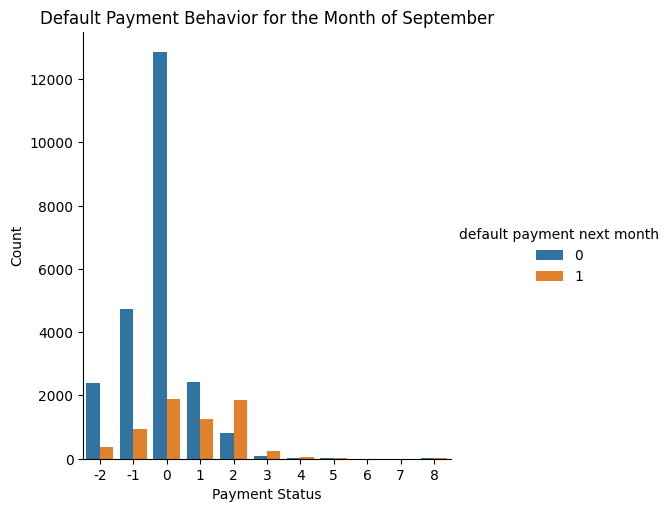

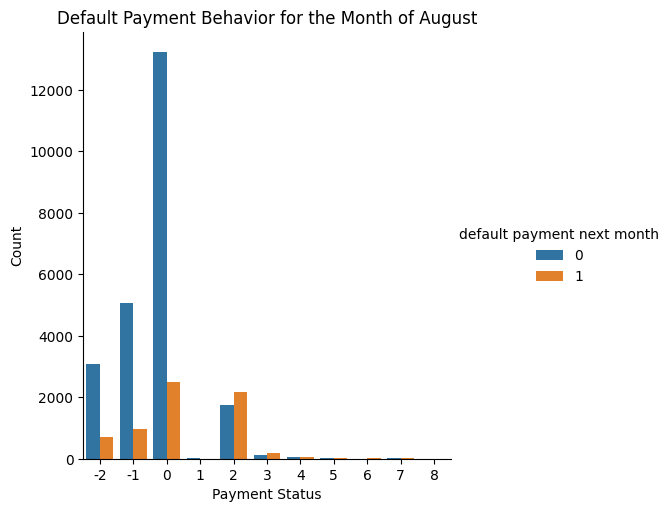

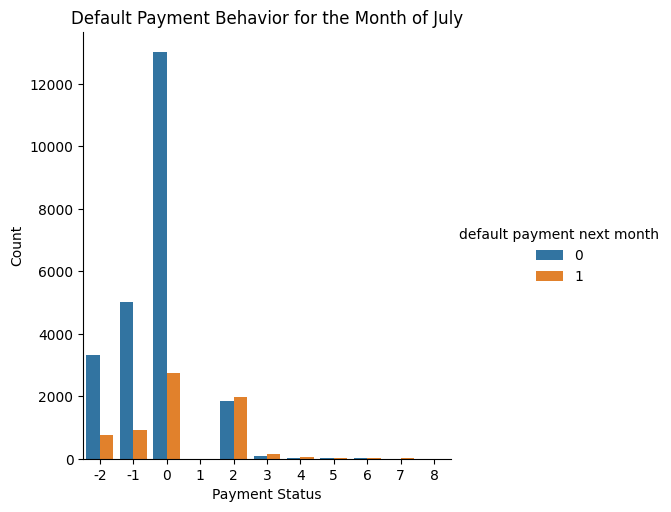

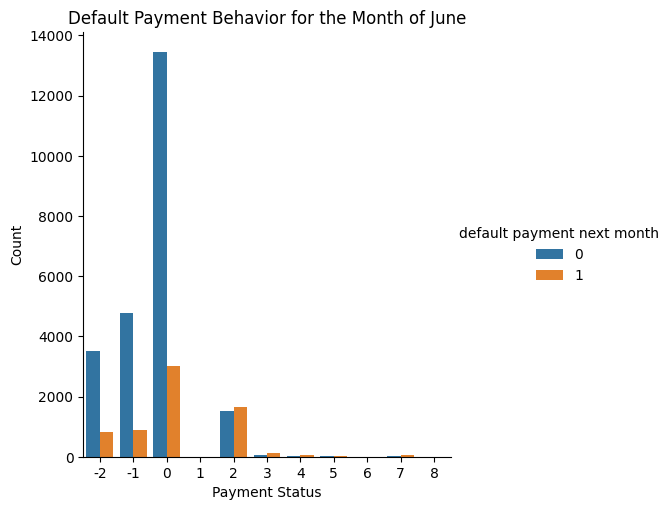

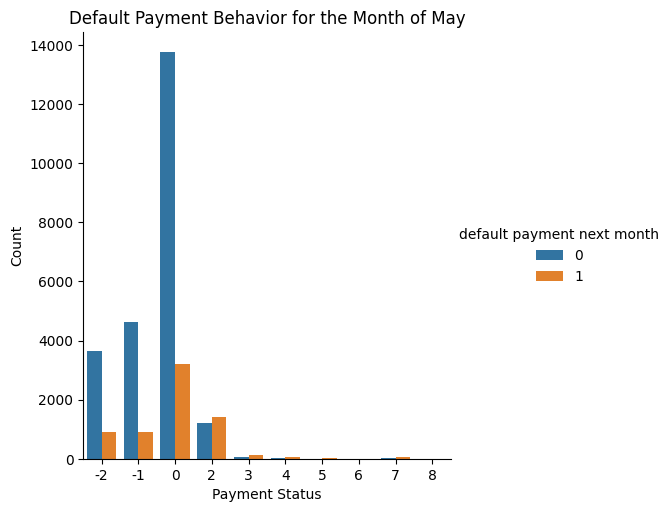

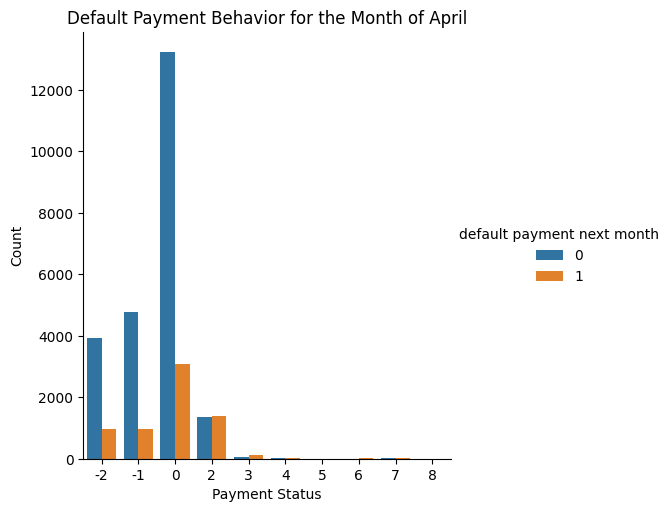

The average percentage of delayed payment in the span of April to September is 13.90 %
The maximum percentage of delayed payments is 22.73 % and it is on the month of September.
The average percentage of delayed payment in the span of April to September that defaulted the next month is 33.27 %
The maximum percentage of delayed payment that defaulted the next month is 51.67 % and it is on the month of September.


In [ ]:
months = ['September', 'August', 'July', 'June', 'May', 'April']

pay_pd_df = pd_df[['PAY_SEPT', 'PAY_AUG', 'PAY_JUL', 'PAY_JUN', 'PAY_MAY', 'PAY_APR']]
default_pay_df = pd_df[pd_df['default payment next month']==1][['PAY_SEPT', 'PAY_AUG', 'PAY_JUL', 'PAY_JUN', 'PAY_MAY', 'PAY_APR']]
delayed_percentage = []
delayed_perc_default = []

for i, month in enumerate(months):
  #Get the percentage of delayed payments
  month_pay_df = pay_pd_df[pay_pd_df.columns[i]].value_counts().reset_index()
  total = month_pay_df[month_pay_df[month_pay_df.columns[0]]>0]['count'].sum()
  percent1 = (total/len(pay_pd_df)) * 100
  delayed_percentage.append(percent1)

  #Get the percentage of defaulted delayed payments
  month_default_pay_df = default_pay_df[default_pay_df.columns[i]].value_counts().reset_index()
  total = month_default_pay_df[month_default_pay_df[month_default_pay_df.columns[0]]>0]['count'].sum()
  percent2 = (total/len(default_pay_df)) * 100
  delayed_perc_default.append(percent2)

  #Plot the graph
  sns.catplot(data=pd_df, kind='count', x=pd_df.columns[i+6], hue='default payment next month')
  plt.title('Default Payment Behavior for the Month of {}'.format(month))
  plt.xlabel('Payment Status')
  plt.ylabel('Count')
  plt.show()

avg_delayed_percentage = sum(delayed_percentage)/len(delayed_percentage)
max_delayed_percentage = max(delayed_percentage)
month_of_max_all = months[np.argmax(delayed_percentage)]
print('The average percentage of delayed payment in the span of April to September is {:.2f} %'.format(avg_delayed_percentage))
print('The maximum percentage of delayed payments is {:.2f} % and it is on the month of {}.'.format(max_delayed_percentage, month_of_max_all))

avg_delayed_per_default = sum(delayed_perc_default)/len(delayed_perc_default)
max_delayed_perc_default = max(delayed_perc_default)
month_of_max_default = months[np.argmax(delayed_perc_default)]
print('The average percentage of delayed payment in the span of April to September that defaulted the next month is {:.2f} %'.format(avg_delayed_per_default))
print('The maximum percentage of delayed payment that defaulted the next month is {:.2f} % and it is on the month of {}.'.format(max_delayed_perc_default, month_of_max_default))

Across all months the borrowers had delayed payments 14% of the time. Where September had the most delayed payments month with 23%.

How about the borrowers that defaulted the next month? After calculations, we can see that the borrowers that defaulted the next month had delayed payment a third of the time. Where the month of September had the most delayed payments half of the time.

In [ ]:
defaulted_delayed_df = pd_df[(pd_df['PAY_SEPT']>0) &
                             (pd_df['PAY_AUG']>0) &
                             (pd_df['PAY_JUL']>0) &
                             (pd_df['PAY_JUN']>0) &
                             (pd_df['PAY_MAY']>0) &
                             (pd_df['PAY_APR']>0)]
default_delayed_count = defaulted_delayed_df['default payment next month'].value_counts()[1]
default_delayed_percentage = (default_delayed_count/len(defaulted_delayed_df)) * 100
print('The percentage of borrowers whom experienced delayed payments are {:.2f} % likely to default the next month.'.format(default_delayed_percentage))

The percentage of borrowers whom experienced delayed payments are 70.32 % likely to default the next month.



We can now move on to the Financial Behavior Section. This section contains all columns of bill statements and previous payments. A similar process can be done to make it easier to read these columns.

In [ ]:
pd_df.rename(columns={'BILL_AMT1':'BILL_AMT_SEPT', 'BILL_AMT2':'BILL_AMT_AUG', 'BILL_AMT3':'BILL_AMT_JUL','BILL_AMT4':'BILL_AMT_JUN','BILL_AMT5':'BILL_AMT_MAY','BILL_AMT6':'BILL_AMT_APR'}, inplace=True)
pd_df.rename(columns={'PAY_AMT1':'PAY_AMT_SEPT', 'PAY_AMT2':'PAY_AMT_AUG', 'PAY_AMT3':'PAY_AMT_JUL','PAY_AMT4':'PAY_AMT_JUN','PAY_AMT5':'PAY_AMT_MAY','PAY_AMT6':'PAY_AMT_APR'}, inplace=True)

An important column can be created by getting the total of all bill amounts and previous payments per borrower.

In [ ]:
pd_df['TOTAL_BILL'] = pd_df[['BILL_AMT_SEPT','BILL_AMT_AUG','BILL_AMT_JUL','BILL_AMT_JUN','BILL_AMT_MAY','BILL_AMT_APR']].sum(axis=1)
pd_df['TOTAL_PAY'] = pd_df[['PAY_AMT_SEPT','PAY_AMT_AUG','PAY_AMT_JUL','PAY_AMT_JUN','PAY_AMT_MAY','PAY_AMT_APR']].sum(axis=1)
pd_df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_SEPT,PAY_AUG,PAY_JUL,PAY_JUN,...,BILL_AMT_APR,PAY_AMT_SEPT,PAY_AMT_AUG,PAY_AMT_JUL,PAY_AMT_JUN,PAY_AMT_MAY,PAY_AMT_APR,default payment next month,TOTAL_BILL,TOTAL_PAY
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,689,0,0,0,0,1,7704,689
1,2,120000,2,2,2,26,-1,2,0,0,...,3261,0,1000,1000,1000,0,2000,1,17077,5000
2,3,90000,2,2,2,34,0,0,0,0,...,15549,1518,1500,1000,1000,1000,5000,0,101653,11018
3,4,50000,2,2,1,37,0,0,0,0,...,29547,2000,2019,1200,1100,1069,1000,0,231334,8388
4,5,50000,1,2,1,57,-1,0,-1,0,...,19131,2000,36681,10000,9000,689,679,0,109339,59049


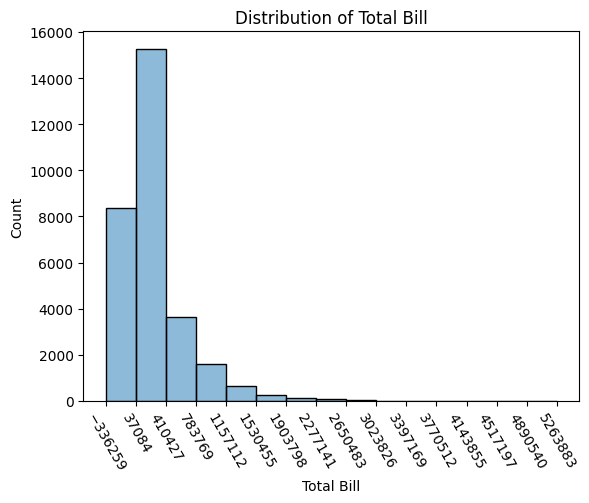

In [ ]:
ticks = np.linspace(pd_df['TOTAL_BILL'].min(), pd_df['TOTAL_BILL'].max(), 16)

sns.histplot(data=pd_df, x='TOTAL_BILL', bins=15, alpha=0.5)
plt.title('Distribution of Total Bill')
plt.ticklabel_format(style='plain', axis='x')
plt.xticks(ticks, rotation=-60)
plt.xlabel('Total Bill')
plt.ylabel('Count')
plt.show()

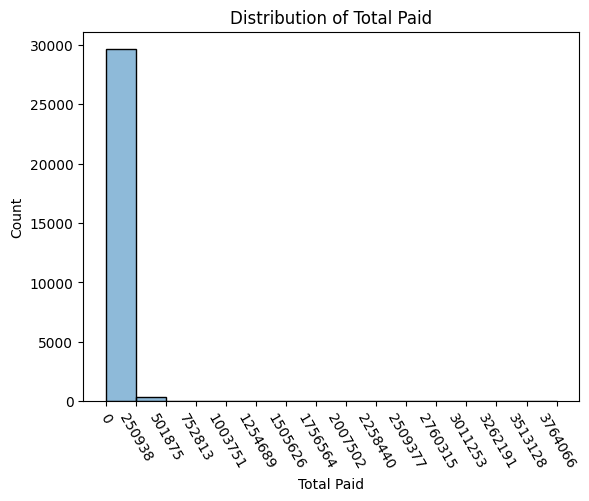

In [ ]:
ticks = np.linspace(pd_df['TOTAL_PAY'].min(), pd_df['TOTAL_PAY'].max(), 16)

sns.histplot(data=pd_df, x='TOTAL_PAY', bins=15, alpha=0.5)
plt.title('Distribution of Total Paid')
plt.ticklabel_format(style='plain', axis='x')
plt.xticks(ticks, rotation=-60)
plt.xlabel('Total Paid')
plt.ylabel('Count')
plt.show()

According to the histogram, most of the borrowers have a total bill between 37,084 to 410,427. We can also observe that there were borrowers with an outstanding total bill of negative. This may indicate that there are borrowers who overpays their credit and has credit balance. However, we can see it more clearly if we plot every month.

In [ ]:
bill_statement = ['BILL_AMT_SEPT','BILL_AMT_AUG','BILL_AMT_JUL','BILL_AMT_JUN','BILL_AMT_MAY','BILL_AMT_APR']
pay_statement = ['PAY_AMT_SEPT','PAY_AMT_AUG','PAY_AMT_JUL','PAY_AMT_JUN','PAY_AMT_MAY','PAY_AMT_APR']

months = ['September', 'August', 'July', 'June', 'May', 'April']

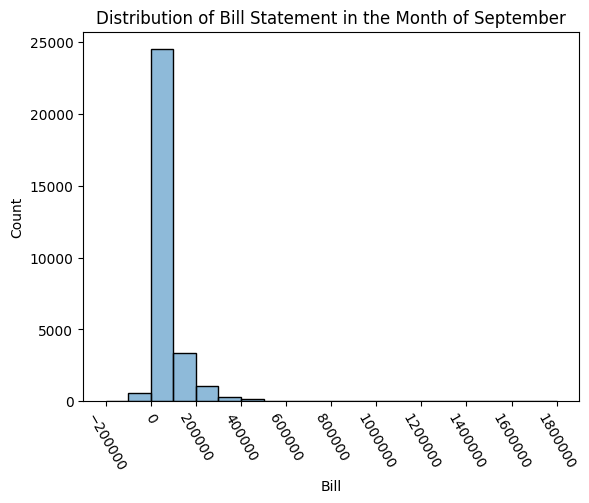

BILL_AMT_SEPT
(0, 100000]           22496
(100000, 200000]       3383
(-100000, 0]           2596
(200000, 300000]       1033
(300000, 400000]        315
(400000, 500000]        130
(500000, 600000]         35
(600000, 700000]          8
(-200000, -100000]        2
(700000, 800000]          1
(900000, 1000000]         1
(800000, 900000]          0
(1000000, 1100000]        0
(1100000, 1200000]        0
(1200000, 1300000]        0
(1300000, 1400000]        0
(1400000, 1500000]        0
(1500000, 1600000]        0
(1600000, 1700000]        0
(1700000, 1800000]        0
Name: count, dtype: int64


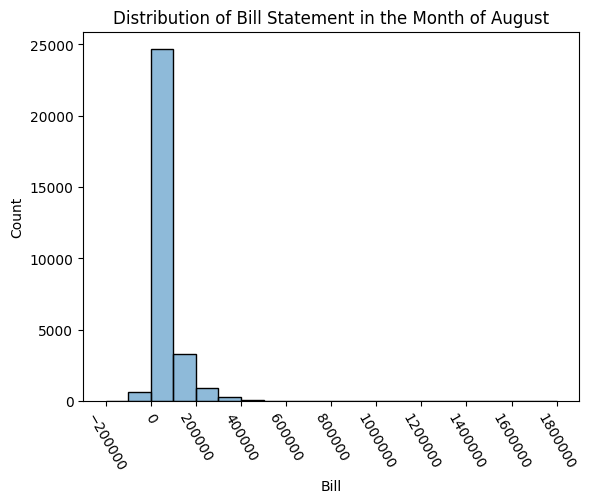

BILL_AMT_AUG
(0, 100000]           22161
(100000, 200000]       3272
(-100000, 0]           3175
(200000, 300000]        946
(300000, 400000]        298
(400000, 500000]        111
(500000, 600000]         31
(600000, 700000]          4
(900000, 1000000]         1
(700000, 800000]          1
(-200000, -100000]        0
(800000, 900000]          0
(1000000, 1100000]        0
(1100000, 1200000]        0
(1200000, 1300000]        0
(1300000, 1400000]        0
(1400000, 1500000]        0
(1500000, 1600000]        0
(1600000, 1700000]        0
(1700000, 1800000]        0
Name: count, dtype: int64


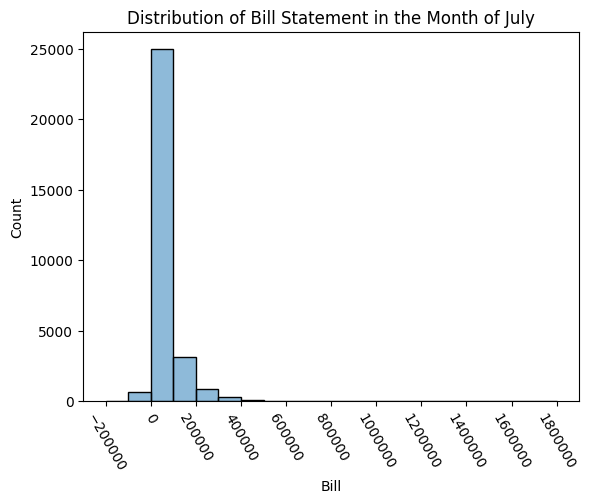

BILL_AMT_JUL
(0, 100000]           22096
(-100000, 0]           3524
(100000, 200000]       3123
(200000, 300000]        853
(300000, 400000]        274
(400000, 500000]        106
(500000, 600000]         17
(600000, 700000]          4
(-200000, -100000]        1
(800000, 900000]          1
(1600000, 1700000]        1
(700000, 800000]          0
(900000, 1000000]         0
(1000000, 1100000]        0
(1200000, 1300000]        0
(1100000, 1200000]        0
(1300000, 1400000]        0
(1400000, 1500000]        0
(1500000, 1600000]        0
(1700000, 1800000]        0
Name: count, dtype: int64


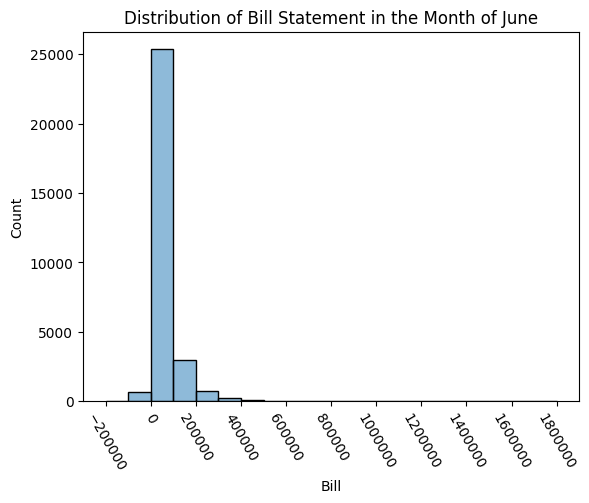

BILL_AMT_JUN
(0, 100000]           22164
(-100000, 0]           3869
(100000, 200000]       2941
(200000, 300000]        709
(300000, 400000]        223
(400000, 500000]         73
(500000, 600000]         16
(600000, 700000]          2
(-200000, -100000]        1
(700000, 800000]          1
(800000, 900000]          1
(900000, 1000000]         0
(1000000, 1100000]        0
(1100000, 1200000]        0
(1200000, 1300000]        0
(1300000, 1400000]        0
(1400000, 1500000]        0
(1500000, 1600000]        0
(1600000, 1700000]        0
(1700000, 1800000]        0
Name: count, dtype: int64


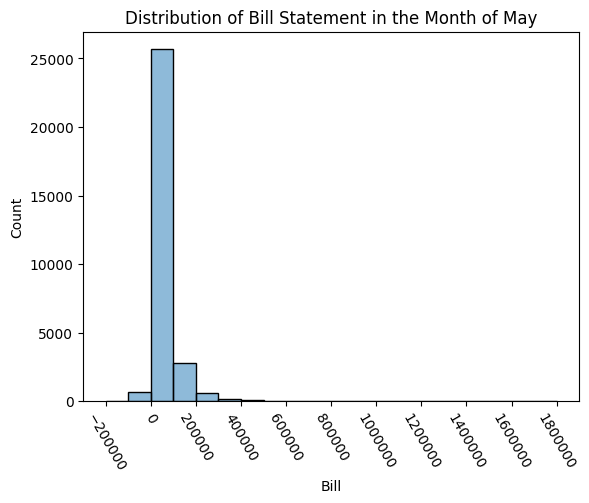

BILL_AMT_MAY
(0, 100000]           22176
(-100000, 0]           4161
(100000, 200000]       2787
(200000, 300000]        624
(300000, 400000]        182
(400000, 500000]         56
(500000, 600000]         12
(900000, 1000000]         1
(800000, 900000]          1
(-200000, -100000]        0
(700000, 800000]          0
(600000, 700000]          0
(1000000, 1100000]        0
(1100000, 1200000]        0
(1200000, 1300000]        0
(1300000, 1400000]        0
(1400000, 1500000]        0
(1500000, 1600000]        0
(1600000, 1700000]        0
(1700000, 1800000]        0
Name: count, dtype: int64


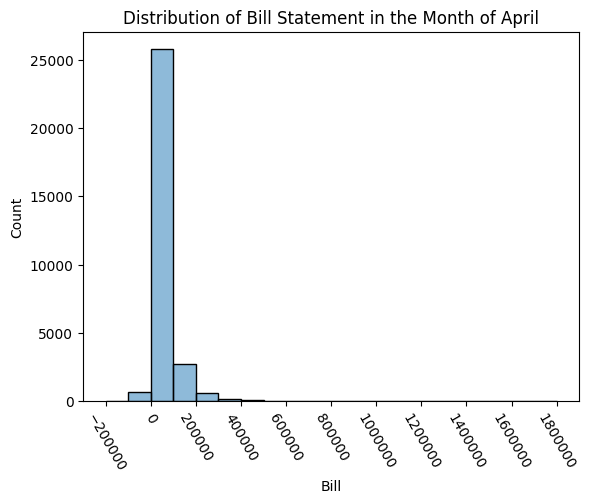

BILL_AMT_APR
(0, 100000]           21748
(-100000, 0]           4705
(100000, 200000]       2723
(200000, 300000]        593
(300000, 400000]        165
(400000, 500000]         54
(500000, 600000]          7
(-200000, -100000]        1
(600000, 700000]          1
(900000, 1000000]         1
(700000, 800000]          0
(800000, 900000]          0
(1000000, 1100000]        0
(1100000, 1200000]        0
(1200000, 1300000]        0
(1300000, 1400000]        0
(1400000, 1500000]        0
(1500000, 1600000]        0
(1600000, 1700000]        0
(1700000, 1800000]        0
Name: count, dtype: int64
The average number of borrowers that have a bill statement between 0 to 100,000 is 22140.


In [ ]:
max_count_list = []
for i, column in enumerate(bill_statement):
  ticks = np.arange(-200000, 1800001, 100000)
  clean_ticks = np.arange(-200000, 1800001, 200000)

  sns.histplot(data=pd_df, x=column, bins=ticks, alpha=0.5)
  plt.title('Distribution of Bill Statement in the Month of {}'.format(months[i]))
  plt.ticklabel_format(style='plain', axis='x')
  plt.xticks(clean_ticks, rotation=-60)
  plt.xlabel('Bill')
  plt.ylabel('Count')
  plt.show()

  binned_bill = pd.cut(pd_df[column], bins=ticks)
  bin_counts = binned_bill.value_counts()
  print(bin_counts)
  max_count = bin_counts.max()
  max_count_list.append(max_count)
avg_count = sum(max_count_list)/len(max_count_list)
print('The average number of borrowers that have a bill statement between 0 to 100,000 is {:.0f}.'.format(avg_count))

Here we can see that the bill amount are concentrated between 0 to 100000 with an average of 22,140 number of borrowers each month. However, since the distribution of borrowers are skewed and don't follow a normal distribution, using the average can be quite misleading for a few borrowers with massive debts that pull the average way up. To find what a normal borrower owes, we use percentiles to split up the data.

In [ ]:
pd_df.describe(include='all')

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_SEPT,PAY_AUG,PAY_JUL,PAY_JUN,...,BILL_AMT_APR,PAY_AMT_SEPT,PAY_AMT_AUG,PAY_AMT_JUL,PAY_AMT_JUN,PAY_AMT_MAY,PAY_AMT_APR,default payment next month,TOTAL_BILL,TOTAL_PAY
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,3.000000e+04
mean,15000.500000,167484.322667,1.603733,1.842267,1.557267,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,...,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200,2.698617e+05,3.165139e+04
std,8660.398374,129747.661567,0.489129,0.744494,0.521405,9.217904,1.123802,1.197186,1.196868,1.169139,...,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062,3.795643e+05,6.082768e+04
min,1.000000,10000.000000,1.000000,1.000000,1.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,...,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000,-3.362590e+05,0.000000e+00
25%,7500.750000,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000,2.868800e+04,6.679750e+03
50%,15000.500000,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,...,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000,1.263110e+05,1.438300e+04
75%,22500.250000,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,...,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000,3.426265e+05,3.350350e+04
max,30000.000000,1000000.000000,2.000000,4.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,...,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000,1.000000,5.263883e+06,3.764066e+06


Here we can see the percentiles of each column since these columns are integers or numbers. These percentiles are '25%', '50%', and '75%'. They are also called as 'quantiles' because they are divided into 4.

In [ ]:
bills = []
percents = [0.25, 0.5, 0.75, 0.99]
for percent in percents:
  quantile = []
  for bill in bill_statement:
    paid_quantile = pd_df[bill].quantile(percent)
    quantile.append(paid_quantile)
  bills.append(quantile)
avg_billed = []
for i in range(len(percents)):
  avg = np.mean(bills[i])
  avg_billed.append(avg)
  print('The average of {}th percentile is {:.2f}.'.format(int(percents[i]*100),avg))

The average of 25th percentile is 2425.92.
The average of 50th percentile is 19649.58.
The average of 75th percentile is 57526.12.
The average of 99th percentile is 313834.50.


Here looking at the middle value, the '50th percentile' or '2nd quantile' shows that half of our borrowers owe an average of 19649.58 from the month of the April to September, which was much lower than earlier. Now for the for '25th percentile' or '1st quantile', a very far amount with an average of 2425.92. Then, we have the '75th percentile' or '3rd quantile' of the borrowers, we can see here quite a big jump. They owe an average of 57526.12. Lastly, anyone above '99th percentile' of an average of 313834.50 is an rare extreme cases such as corporate or heavy spender account. These percentiles allows us to focus on the everyday borrowers without letting those giant numbers to ruin our analysis.

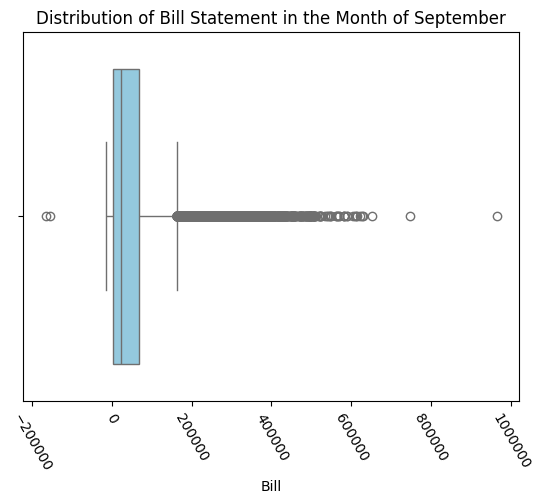

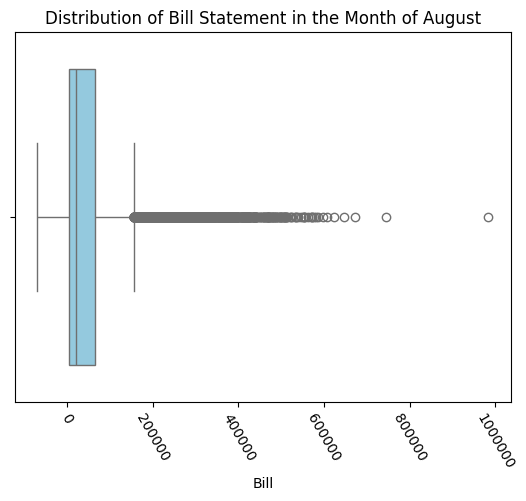

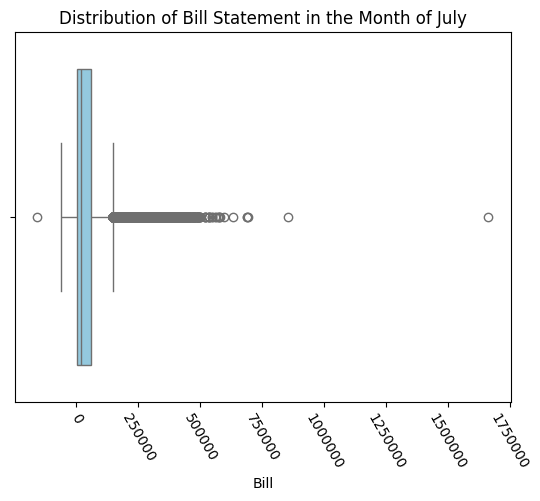

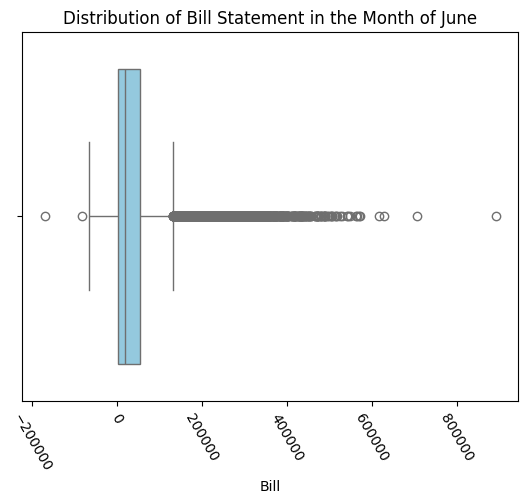

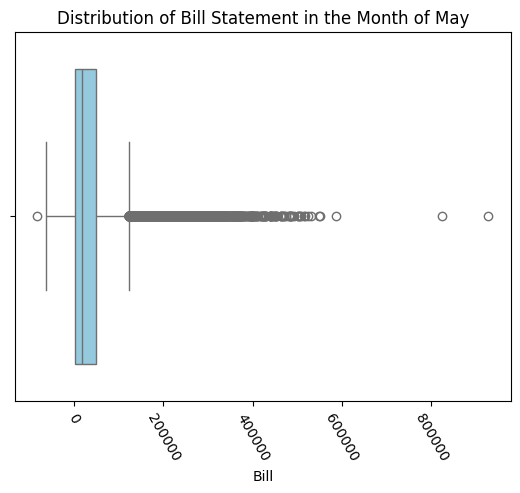

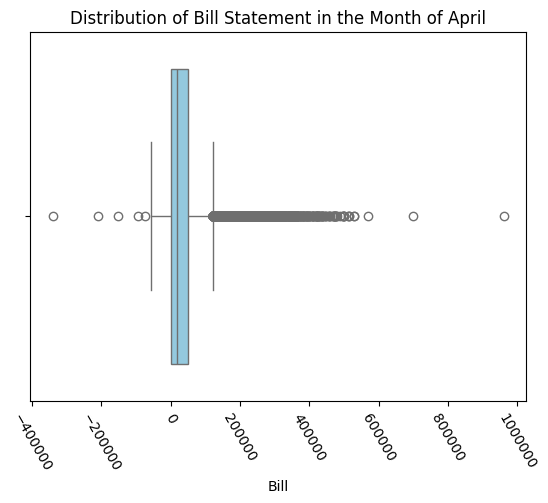

In [ ]:
for i, column in enumerate(bill_statement):
  sns.boxplot(data=pd_df, x=column, color='skyblue')
  plt.title('Distribution of Bill Statement in the Month of {}'.format(months[i]))
  plt.ticklabel_format(style='plain', axis='x')
  plt.xticks(rotation=-60)
  plt.xlabel('Bill')
  plt.show()

Due to the presence of unsual high and low outliers, percentiles offer a much more accurate analytical baseline. On the other we will look into previous payment of the borrowers from April to September. This time we will skip plotting of data and go directly to the percentiles.

In [ ]:
paids = []
percents = [0.25, 0.5, 0.75, 0.99]
for percent in percents:
  quantile = []
  for paid in pay_statement:
    paid_quantile = pd_df[paid].quantile(percent)
    quantile.append(paid_quantile)
  paids.append(quantile)
avg_paid = []
for i in range(len(percents)):
  avg = np.mean(paids[i])
  avg_paid.append(avg)
  print('The average of {}th percentile is {:.2f}.'.format(int(percents[i]*100),avg))

The average of 25th percentile is 481.54.
The average of 50th percentile is 1734.83.
The average of 75th percentile is 4425.96.
The average of 99th percentile is 71409.04.


In [ ]:
for i in range(len(percents)):
  percentage = (avg_paid[i]/avg_billed[i])*100
  print('The percentage paid by the {}th percentile is {:.2f}%.'.format(int(percents[i]*100),percentage))

The percentage paid by the 25th percentile is 19.85%.
The percentage paid by the 50th percentile is 8.83%.
The percentage paid by the 75th percentile is 7.69%.
The percentage paid by the 99th percentile is 22.75%.


Here compared to the what borrowers owe, each percentile paid a very low amount having a maximum of 22.75% on only the 99th percentile. Where the '75th percentile' having the lowest percentage of 7.69% out of all the bills. However, these results can't be use to explain or analyze the consistency of payments of borrowers due to the fact that there are borrowers who have a total previous payments of 0 or have negative bill statement. This means that they are not required to pay or they already paid due to their credit balance.

To measure the consistency of borrowers across the 6 months. Consider these:

For each borrower, a binary flag will be created per month defined as **Compliant**, 1 if **PAY_AMT**$_m > 0$ or **BILL_AMT**$_m $$\ge$$ 0$ and $0$ otherwise where $m$ is month, i.e. **Consistency Score** = $\frac{\sum{Compliant}}{6} * 100$. This will be formula to measure the percentage of how much the borrower is compliant.


In [ ]:
monthly_pairs = [
    ('BILL_AMT_SEPT', 'PAY_AMT_SEPT'),
    ('BILL_AMT_AUG', 'PAY_AMT_AUG'),
    ('BILL_AMT_JUL', 'PAY_AMT_JUL'),
    ('BILL_AMT_JUN', 'PAY_AMT_JUN'),
    ('BILL_AMT_MAY', 'PAY_AMT_MAY'),
    ('BILL_AMT_APR', 'PAY_AMT_APR')
]

In [ ]:
compliance_matrix = pd.DataFrame()
for i, (bill_col, pay_col) in enumerate(monthly_pairs, 1):
  compliance_matrix[f'Consistency month {i}'] =  ((pd_df[pay_col] > 0) | (pd_df[bill_col] <= 0)).astype('int64')
pd_df['Consistency (%)'] = ((compliance_matrix.sum(axis=1))/6)*100
pd_df

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_SEPT,PAY_AUG,PAY_JUL,PAY_JUN,...,PAY_AMT_SEPT,PAY_AMT_AUG,PAY_AMT_JUL,PAY_AMT_JUN,PAY_AMT_MAY,PAY_AMT_APR,default payment next month,TOTAL_BILL,TOTAL_PAY,Consistency (%)
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,689,0,0,0,0,1,7704,689,66.666667
1,2,120000,2,2,2,26,-1,2,0,0,...,0,1000,1000,1000,0,2000,1,17077,5000,66.666667
2,3,90000,2,2,2,34,0,0,0,0,...,1518,1500,1000,1000,1000,5000,0,101653,11018,100.000000
3,4,50000,2,2,1,37,0,0,0,0,...,2000,2019,1200,1100,1069,1000,0,231334,8388,100.000000
4,5,50000,1,2,1,57,-1,0,-1,0,...,2000,36681,10000,9000,689,679,0,109339,59049,100.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,29996,220000,1,3,1,39,0,0,0,0,...,8500,20000,5003,3047,5000,1000,0,725349,42550,100.000000
29996,29997,150000,1,3,2,43,-1,-1,-1,-1,...,1837,3526,8998,129,0,0,0,21182,14490,83.333333
29997,29998,30000,1,2,2,37,4,3,2,-1,...,0,0,22000,4200,2000,3100,1,70496,31300,66.666667
29998,29999,80000,1,3,1,41,1,-1,0,0,...,85900,3409,1178,1926,52964,1804,1,266611,147181,100.000000


In [ ]:
consistency = pd_df['Consistency (%)'].sum()/len(pd_df)
print('The consistency of payments is {:.2f}%'.format(consistency))

The consistency of payments is 88.49%


Overall, the borrowers show a high consistency in making their payments. We will be moving forward to Bivariate Analysis. First an analysis between the target variable and demographics variables must be done.

In [ ]:
default_by_sex = pd_df.groupby('SEX')['default payment next month'].mean().mul(100)
default_by_sex

,default payment next month
SEX,
1,24.167227
2,20.776281


In [ ]:
default_by_education = pd_df.groupby('EDUCATION')['default payment next month'].mean().mul(100)
default_by_education

,default payment next month
EDUCATION,
1,19.234766
2,23.734854
3,25.157616
4,7.051282


In [ ]:
default_by_marriage = pd_df.groupby('MARRIAGE')['default payment next month'].mean().mul(100)
default_by_marriage

,default payment next month
MARRIAGE,
1,23.471704
2,20.928339
3,23.607427


In order to analyze both 'AGE' and target variable, its values need to be manageable. As we can see below, the unique values of 'AGE' column is more than 10. We will create a group column to make this more manageable.

In [ ]:
pd_df['AGE'].unique()


array([24, 26, 34, 37, 57, 29, 23, 28, 35, 51, 41, 30, 49, 39, 40, 27, 47,
       33, 32, 54, 58, 22, 25, 31, 46, 42, 43, 45, 56, 44, 53, 38, 63, 36,
       52, 48, 55, 60, 50, 75, 61, 73, 59, 21, 67, 66, 62, 70, 72, 64, 65,
       71, 69, 68, 79, 74])

In [ ]:
bins = [20, 30, 40, 50, 60, 70, 80]
labels = ['21-30', '31-40', '41-50', '51-60', '61-70', '71-80']

pd_df['AGE_GROUP'] = pd.cut(pd_df['AGE'], bins=bins, labels=labels, include_lowest=True)
pd_df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_SEPT,PAY_AUG,PAY_JUL,PAY_JUN,...,PAY_AMT_AUG,PAY_AMT_JUL,PAY_AMT_JUN,PAY_AMT_MAY,PAY_AMT_APR,default payment next month,TOTAL_BILL,TOTAL_PAY,Consistency (%),AGE_GROUP
0,1,20000,2,2,1,24,2,2,-1,-1,...,689,0,0,0,0,1,7704,689,66.666667,21-30
1,2,120000,2,2,2,26,-1,2,0,0,...,1000,1000,1000,0,2000,1,17077,5000,66.666667,21-30
2,3,90000,2,2,2,34,0,0,0,0,...,1500,1000,1000,1000,5000,0,101653,11018,100.000000,31-40
3,4,50000,2,2,1,37,0,0,0,0,...,2019,1200,1100,1069,1000,0,231334,8388,100.000000,31-40
4,5,50000,1,2,1,57,-1,0,-1,0,...,36681,10000,9000,689,679,0,109339,59049,100.000000,51-60


In [ ]:
default_by_age = pd_df.groupby('AGE_GROUP')['default payment next month'].mean().mul(100)
default_by_age

/tmp/ipykernel_432/2292955413.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  default_by_age = pd_df.groupby('AGE_GROUP')['default payment next month'].mean().mul(100)


,default payment next month
AGE_GROUP,
21-30,22.437120
31-40,20.433119
41-50,23.297252
51-60,25.237857
61-70,26.459144
71-80,33.333333


The statistical result of bivariate analysis of demographic variables and the target variable tell us the following:
* Male exhibits higher observed default rate than female with a difference of 3.39 %.
* University and high school graduate borrowers exhibits high default rate with the university graduate borrower the highest default rate among all.
* Borrowers whom categorizes as other in 'MARRIAGE' column exhibits the highest default rate with married borrowers falling short by 0.14 %.
* Borrowers exhibits a strictly increasing default rate after the age of 30. Peaking at 33.33 % by the age of 71 to 80.

These statistics suggests potential association with the credit default behavior however, these requires further investigation. A bivariate will be done for the credit limit balance of the borrowers. In analyzing the column 'LIMIT_BAL', the same scenario is present similar on column 'AGE'. A categorization will be done in order for the values to be manageable and understood easily.

In [ ]:
bins = [0, 100000, 200000, 300000, 400000, 500000, 600000, 700000, 800000, 900000, 1000000]
labels = ['0-100,000','100,001-200,000','200,001-300,000','300,001-400,000','400,001-500,000',
          '500,001-600,000','600,001-700,000','700,001-800,000','800,001-900,000','900,001-1,000,000']
pd_df['LIMIT_BAL_GROUP'] = pd.cut(pd_df['LIMIT_BAL'], bins=bins, labels=labels, include_lowest=True)

In [ ]:
default_by_credit_limit = pd_df.groupby('LIMIT_BAL_GROUP')['default payment next month'].mean().mul(100).fillna(0)
default_by_credit_limit

/tmp/ipykernel_432/776707349.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  default_by_credit_limit = pd_df.groupby('LIMIT_BAL_GROUP')['default payment next month'].mean().mul(100).fillna(0)


,default payment next month
LIMIT_BAL_GROUP,
"0-100,000",29.476716
"100,001-200,000",19.479695
"200,001-300,000",16.050603
"300,001-400,000",14.063066
"400,001-500,000",12.140175
"500,001-600,000",13.385827
"600,001-700,000",5.357143
"700,001-800,000",13.636364
"800,001-900,000",0.000000


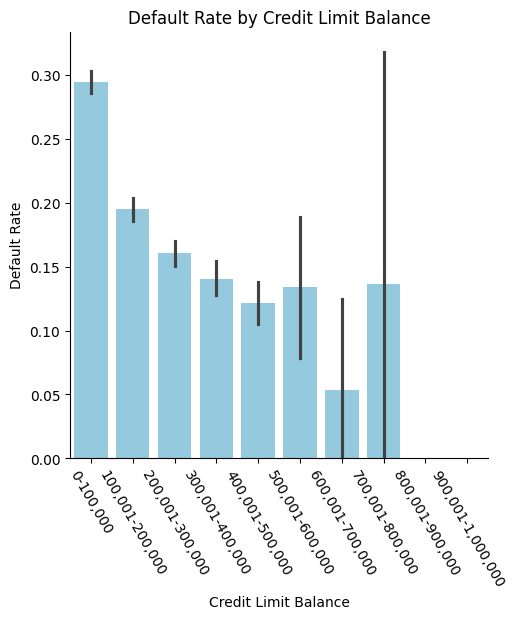

In [ ]:
sns.catplot(data=pd_df, kind='bar', x='LIMIT_BAL_GROUP', y='default payment next month', color='skyblue')
plt.title('Default Rate by Credit Limit Balance')
plt.xticks(rotation=-60)
plt.xlabel('Credit Limit Balance')
plt.ylabel('Default Rate')
plt.show()

Borrowers with a credit balance of 0 to 100,000 exhibits a high default rate decreasing as the credit balance increases. However, this inverse relationship is only present lower than 800,001 credit balance. This suggest that 'LIMIT_BAL_GROUP' has a hig chance of being a predictor for the target variable. Now, we will move forward to borrowers payment behavior.

In [ ]:
behavior = ['PAY_SEPT', 'PAY_AUG', 'PAY_JUL', 'PAY_JUN', 'PAY_MAY', 'PAY_APR']
percentage_delayed = []
for i, column in enumerate(behavior):
  # Group by behavior and calculate both mean (default rate) and count (number of borrowers)
  default_rate = pd_df.groupby(column)['default payment next month'].agg(['mean', 'count'])
  default_rate['mean'] = default_rate['mean'].mul(100)
  default_rate['Percentage of Borrowers (%)'] = (default_rate['count']/default_rate['count'].sum())*100
  default_rate.rename(columns={'mean': 'Default Rate (%)', 'count': 'Number of Borrowers'}, inplace=True)

  percentage = default_rate.iloc[3:]['Percentage of Borrowers (%)'].sum()
  percentage_delayed.append(percentage)

  print('The default rate by {}.'.format(column))
  print(default_rate)
  print()
avg_percentage_delayed = sum(percentage_delayed)/len(percentage_delayed)
print('The average percentage of borrowers that experienced delayed payments is {:.2f} %.'.format(avg_percentage_delayed))

The default rate by PAY_SEPT.
          Default Rate (%)  Number of Borrowers  Percentage of Borrowers (%)
PAY_SEPT                                                                    
-2               13.229431                 2759                     9.196667
-1               16.778051                 5686                    18.953333
 0               12.811291                14737                    49.123333
 1               33.947939                 3688                    12.293333
 2               69.141357                 2667                     8.890000
 3               75.776398                  322                     1.073333
 4               68.421053                   76                     0.253333
 5               50.000000                   26                     0.086667
 6               54.545455                   11                     0.036667
 7               77.777778                    9                     0.030000
 8               57.894737                   1

Observe that the borrowers without payment delays have a lower default rate having its highest rate at 20 %, where as borrowers with delay payments which has a much higher default rate but inconsistent across months. However, as establish by the earlier analysis, delayed borrowers form a distinct minority, having an average of 13.9 % of the dataset. This severe class imbalance means that while the risk of default is concentrated heavily within the delayed cohort, the overall portfolio's default rate remains relatively low.

In [ ]:
heatmap_percentage = pd.DataFrame()

for column in behavior:
  heatmap_percentage[column] = pd_df.groupby(column)['default payment next month'].mean()
heatmap_percentage = heatmap_percentage.fillna(0)
heatmap_percentage.index.name = 'Payment Status'
heatmap_percentage

,PAY_SEPT,PAY_AUG,PAY_JUL,PAY_JUN,PAY_MAY,PAY_APR
Payment Status,,,,,,
-2,0.132294,0.182708,0.185312,0.192502,0.196876,0.200409
-1,0.167781,0.159669,0.155945,0.158959,0.161943,0.169861
0,0.128113,0.159123,0.174512,0.183288,0.188529,0.188444
1,0.339479,0.178571,0.250000,0.500000,0.000000,0.000000
2,0.691414,0.556150,0.515580,0.523267,0.541889,0.506508
3,0.757764,0.616564,0.575000,0.611111,0.634831,0.641304
4,0.684211,0.505051,0.578947,0.666667,0.607143,0.632653
5,0.500000,0.600000,0.571429,0.514286,0.588235,0.538462
6,0.545455,0.750000,0.608696,0.400000,0.750000,0.736842


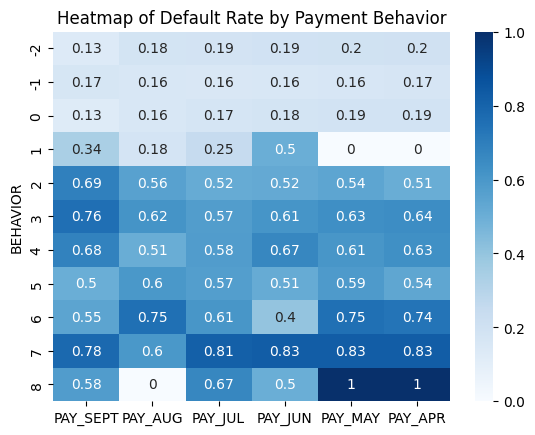

In [ ]:
sns.heatmap(data=heatmap_percentage, annot=True, cmap='Blues')
plt.title('Heatmap of Default Rate by Payment Behavior')
plt.ylabel('BEHAVIOR')
plt.show()

In [ ]:
heatmap_number = pd.DataFrame()

for column in behavior:
  heatmap_number[column] = pd_df.groupby(column)['default payment next month'].count()
heatmap_number = heatmap_number.fillna(0)
heatmap_number.index.name = 'Payment Status'
heatmap_number

,PAY_SEPT,PAY_AUG,PAY_JUL,PAY_JUN,PAY_MAY,PAY_APR
Payment Status,,,,,,
-2,2759,3782,4085,4348,4546.0,4895.0
-1,5686,6050,5938,5687,5539.0,5740.0
0,14737,15730,15764,16455,16947.0,16286.0
1,3688,28,4,2,0.0,0.0
2,2667,3927,3819,3159,2626.0,2766.0
3,322,326,240,180,178.0,184.0
4,76,99,76,69,84.0,49.0
5,26,25,21,35,17.0,13.0
6,11,12,23,5,4.0,19.0


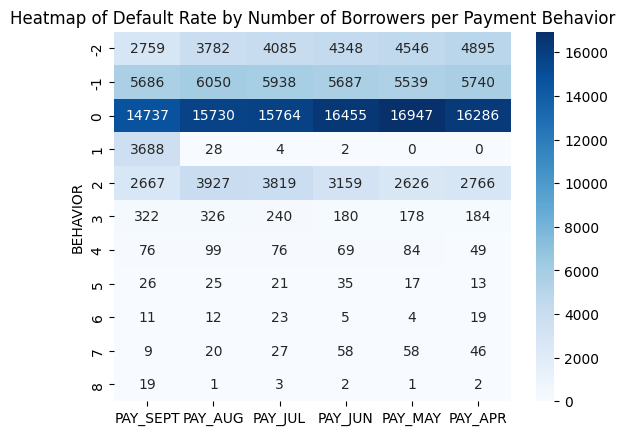

In [ ]:
sns.heatmap(data=heatmap_number, annot=True, fmt='.0f', cmap='Blues')
plt.title('Heatmap of Default Rate by Number of Borrowers per Payment Behavior')
plt.ylabel('BEHAVIOR')
plt.show()

We can see this more clearly in the heatmap. Moving forward, we will now analyze the relationship between target variable and bill statement and previous payment.

In [ ]:
heatmap_bill = pd.DataFrame()
for column in bill_statement:
  ticks = np.arange(-200000, 1800001, 100000)
  binned_bill = pd.cut(pd_df[column], bins=ticks)
  bin_counts = pd_df.groupby(binned_bill)['default payment next month'].mean() * 100
  heatmap_bill[column] = bin_counts
heatmap_bill = heatmap_bill.rename(columns={'BILL_AMT_SEPT':'Sept', 'BILL_AMT_AUG': 'Aug', 'BILL_AMT_JUL': 'Jul', 'BILL_AMT_JUN': 'Jun', 'BILL_AMT_MAY': 'May', 'BILL_AMT_APR': 'Apr'})
heatmap_bill = heatmap_bill.fillna(0)
heatmap_bill.index.name = 'Bill Amount Group'
heatmap_bill


/tmp/ipykernel_432/3188356563.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bin_counts = pd_df.groupby(binned_bill)['default payment next month'].mean() * 100
/tmp/ipykernel_432/3188356563.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bin_counts = pd_df.groupby(binned_bill)['default payment next month'].mean() * 100
/tmp/ipykernel_432/3188356563.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bin_counts =

,Sept,Aug,Jul,Jun,May,Apr
Bill Amount Group,,,,,,
"(-200000, -100000]",0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
"(-100000, 0]",24.768875,23.433071,23.240636,23.235978,23.912521,23.060574
"(0, 100000]",22.386202,22.426786,22.411296,22.324490,22.050866,22.185948
"(100000, 200000]",19.154597,19.254279,19.212296,19.177151,19.878005,19.831069
"(200000, 300000]",18.296225,18.710359,19.109027,20.169252,20.833333,21.416526
"(300000, 400000]",22.857143,24.496644,25.547445,25.560538,25.274725,24.242424
"(400000, 500000]",23.846154,25.225225,23.584906,23.287671,28.571429,31.481481
"(500000, 600000]",42.857143,45.161290,41.176471,50.000000,41.666667,14.285714
"(600000, 700000]",25.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [ ]:
heatmap_pay = pd.DataFrame()
for column in pay_statement:
  ticks = np.arange(-200000, 1800001, 100000)
  binned_pay = pd.cut(pd_df[column], bins=ticks)
  bin_counts = pd_df.groupby(binned_pay)['default payment next month'].mean() * 100
  heatmap_pay[column] = bin_counts
heatmap_pay = heatmap_pay.rename(columns={'PAY_AMT_SEPT':'Sept', 'PAY_AMT_AUG': 'Aug', 'PAY_AMT_JUL': 'Jul', 'PAY_AMT_JUN': 'Jun', 'PAY_AMT_MAY': 'May', 'PAY_AMT_APR': 'Apr'})
heatmap_pay = heatmap_pay.fillna(0)
heatmap_pay.index.name = 'Previous Payment Group'
heatmap_pay


/tmp/ipykernel_432/666353000.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bin_counts = pd_df.groupby(binned_pay)['default payment next month'].mean() * 100
/tmp/ipykernel_432/666353000.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bin_counts = pd_df.groupby(binned_pay)['default payment next month'].mean() * 100
/tmp/ipykernel_432/666353000.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bin_counts = pd_d

,Sept,Aug,Jul,Jun,May,Apr
Previous Payment Group,,,,,,
"(-200000, -100000]",0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
"(-100000, 0]",35.949705,33.339511,32.355898,31.101748,29.389825,28.969748
"(0, 100000]",19.250467,19.747624,19.626913,19.739817,20.075185,20.046899
"(100000, 200000]",9.174312,7.638889,12.318841,10.434783,13.008130,11.173184
"(200000, 300000]",10.000000,6.451613,18.181818,8.695652,10.526316,16.666667
"(300000, 400000]",0.000000,28.571429,8.333333,0.000000,20.000000,20.000000
"(400000, 500000]",0.000000,0.000000,0.000000,33.333333,0.000000,0.000000
"(500000, 600000]",0.000000,0.000000,100.000000,0.000000,0.000000,0.000000
"(600000, 700000]",0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


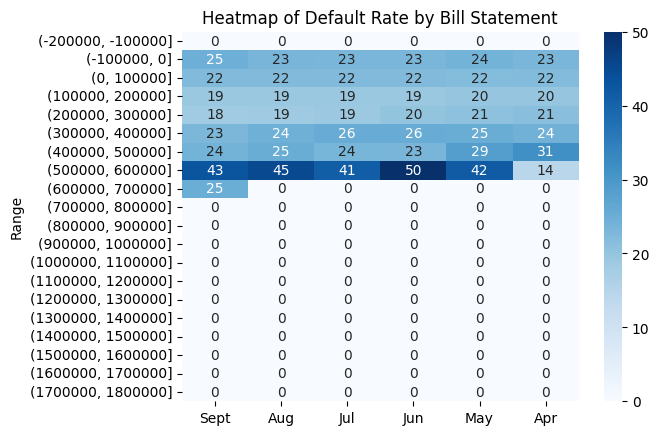

In [ ]:
sns.heatmap(data=heatmap_bill, annot=True, fmt='.0f', cmap='Blues')
plt.title('Heatmap of Default Rate by Bill Statement')
plt.ylabel('Range')
plt.show()

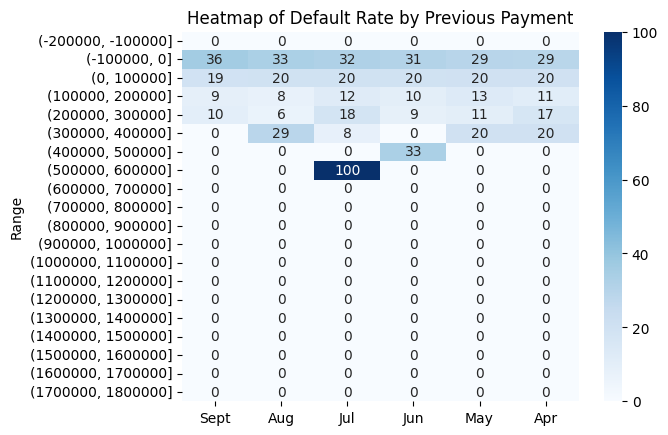

In [ ]:
sns.heatmap(data=heatmap_pay, annot=True, fmt='.0f', cmap='Blues')
plt.title('Heatmap of Default Rate by Previous Payment')
plt.ylabel('Range')
plt.show()

As seen in the heatmap of bill statement columns, borrowers which owe 500,000 t0 600,000 exhibits a high default rate and then decreases and stays stable between 19 % to 23 % until a bill statement of -200,000 to -100,000. An obvious result be seen in the heatmap of the previous payment. Borrowers who did not pay that month exhibits a high possibility of default rate. However, maybe due to the dataset, on july a borrower that paid 500,000 to 600,000 defaulted the next month.

We will move on model preparation by feature engineering the following:
* Credit Utilization Ratio
* Delinquency Frequency

In [ ]:
for i, col in enumerate(bill_statement):
  pd_df[f'{col}_UTIL'] = (np.maximum(0, pd_df[col])/pd_df['LIMIT_BAL']) * 100
  pd_df[f'{col}_UTIL'] = pd_df[f'{col}_UTIL'].fillna(0)


In [ ]:
pd_df.rename(columns={'BILL_AMT_SEPT_UTIL':'CREDIT_UTIL_SEPT',
                      'BILL_AMT_AUG_UTIL':'CREDIT_UTIL_AUG',
                      'BILL_AMT_JUL_UTIL':'CREDIT_UTIL_JUL',
                      'BILL_AMT_JUN_UTIL':'CREDIT_UTIL_JUN',
                      'BILL_AMT_MAY_UTIL':'CREDIT_UTIL_MAY',
                      'BILL_AMT_APR_UTIL':'CREDIT_UTIL_APR'}, inplace=True)

In [ ]:
pd_df['CREDIT_UTIL_AVG'] = (pd_df['CREDIT_UTIL_SEPT'] + pd_df['CREDIT_UTIL_AUG'] + pd_df['CREDIT_UTIL_JUL'] + pd_df['CREDIT_UTIL_JUN'] + pd_df['CREDIT_UTIL_MAY'] + pd_df['CREDIT_UTIL_APR'])/6

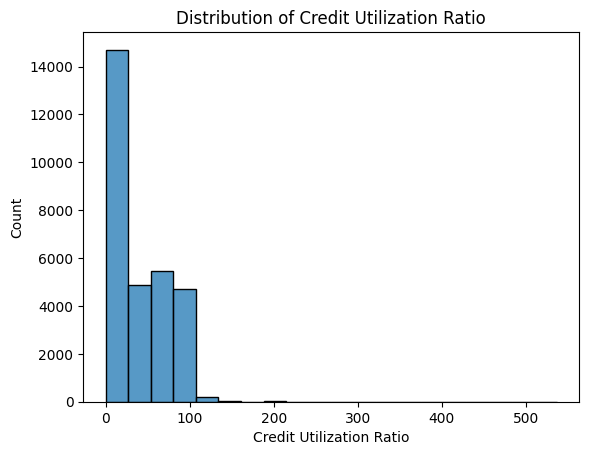

In [ ]:
sns.histplot(data=pd_df, x='CREDIT_UTIL_AVG', bins=20)
plt.title('Distribution of Credit Utilization Ratio')
plt.ticklabel_format(style='plain', axis='x')
plt.xlabel('Credit Utilization Ratio')
plt.ylabel('Count')
plt.show()

As we can see, there are values of credit utilization ratio greater than 100. This requires further investigation.

In [ ]:
pd_df[pd_df['CREDIT_UTIL_AVG']>100]

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_SEPT,PAY_AUG,PAY_JUL,PAY_JUN,...,Consistency (%),AGE_GROUP,LIMIT_BAL_GROUP,CREDIT_UTIL_SEPT,CREDIT_UTIL_AUG,CREDIT_UTIL_JUL,CREDIT_UTIL_JUN,CREDIT_UTIL_MAY,CREDIT_UTIL_APR,CREDIT_UTIL_AVG
189,190,20000,2,2,2,31,1,5,4,4,...,33.333333,31-40,"0-100,000",108.515000,105.435000,107.305000,104.175000,101.095000,102.435000,104.826667
221,222,330000,2,3,2,45,0,0,0,0,...,100.000000,41-50,"300,001-400,000",101.574545,101.501212,101.674848,101.169697,101.745455,100.036667,101.283737
388,389,150000,1,2,1,43,0,0,0,0,...,100.000000,41-50,"100,001-200,000",102.166000,102.699333,104.348667,106.435333,108.577333,105.172667,104.899889
395,396,140000,2,1,2,27,0,0,0,0,...,100.000000,21-30,"100,001-200,000",101.734286,102.932143,102.822857,101.850000,101.892857,101.871429,102.183929
404,405,160000,2,1,2,29,2,2,2,2,...,66.666667,21-30,"100,001-200,000",100.270000,102.447500,99.797500,104.308125,106.311250,96.125000,101.543229
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29896,29897,70000,1,3,1,45,2,2,2,2,...,66.666667,41-50,"0-100,000",102.265714,102.318571,101.457143,96.197143,101.098571,98.510000,100.307857
29899,29900,140000,1,1,2,29,0,0,0,0,...,100.000000,21-30,"100,001-200,000",101.460000,101.490714,182.747143,100.040714,71.555000,72.052143,104.890952
29901,29902,50000,1,2,2,29,1,2,0,0,...,83.333333,21-30,"0-100,000",101.690000,97.500000,206.972000,101.180000,100.496000,98.774000,117.768667
29920,29921,50000,1,4,1,45,2,0,0,0,...,83.333333,41-50,"0-100,000",143.854000,147.028000,150.746000,101.894000,102.040000,0.000000,107.593667


In [ ]:
pd_df[pd_df['CREDIT_UTIL_AVG']==pd_df['CREDIT_UTIL_AVG'].max()].transpose()

,3796
0,
ID,3797
LIMIT_BAL,20000
SEX,2
EDUCATION,2
MARRIAGE,2
AGE,32
PAY_SEPT,0
PAY_AUG,0
PAY_JUL,0


In [ ]:
pd_df[pd_df['CREDIT_UTIL_AVG']>100][['BILL_AMT_SEPT','BILL_AMT_AUG','BILL_AMT_JUL','BILL_AMT_JUN','BILL_AMT_MAY','BILL_AMT_APR','CREDIT_UTIL_AVG']].sort_values('CREDIT_UTIL_AVG',ascending=False).head(20)

,BILL_AMT_SEPT,BILL_AMT_AUG,BILL_AMT_JUL,BILL_AMT_JUN,BILL_AMT_MAY,BILL_AMT_APR,CREDIT_UTIL_AVG
3796,129106,127610,107828,102937,98525,77711,536.430833
20635,82812,85352,91161,92910,98710,150,375.912500
21791,170536,175143,180162,190202,209923,55491,272.626944
9063,73404,75132,77264,74319,9968,10769,267.380000
24765,127510,123969,128267,139912,136604,134705,263.655667
13665,74510,75262,49919,43303,27929,15530,238.710833
16864,96258,69707,71904,62630,57406,46231,224.520000
16702,118587,89271,91157,30420,30384,29774,216.440556
25731,47751,-215,855086,632,632,124542,214.300625
2898,66599,67259,69521,16970,17326,17688,212.802500


As we have seen, there are borrowers who utilized past their credit limit. These requires further investigation but since we do not have enough information or data about these. We can only get this far. We will now move on.

Another feature that will be created, named 'IS_DELINQUENT'. Borrowers will be considered as being delinquent when they missed two consecutive payments. This mean that if a borrower has two consecutive columns with PAY_AMT_m = 0.

In [ ]:
pd_df['IS_DELINQUENT'] = ((pd_df['PAY_AMT_APR'] == 0) & (pd_df['PAY_AMT_MAY'] == 0))|((pd_df['PAY_AMT_MAY'] == 0) & (pd_df['PAY_AMT_JUN'] == 0))|((pd_df['PAY_AMT_JUN'] == 0) & (pd_df['PAY_AMT_JUL'] == 0))|((pd_df['PAY_AMT_JUL'] == 0) & (pd_df['PAY_AMT_AUG'] == 0))|((pd_df['PAY_AMT_AUG'] == 0) & (pd_df['PAY_AMT_SEPT'] == 0))
pd_df['IS_DELINQUENT'] = pd_df['IS_DELINQUENT'].astype('int64')

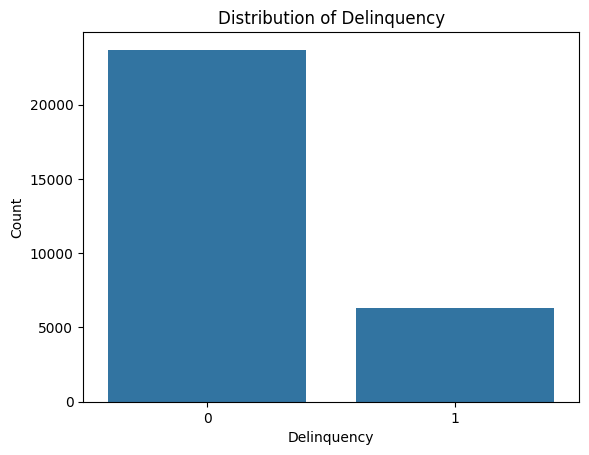

In [ ]:
sns.countplot(data=pd_df, x='IS_DELINQUENT')
plt.title('Distribution of Delinquency')
plt.xlabel('Delinquency')
plt.ylabel('Count')
plt.show()

In [ ]:
pd_df['IS_DELINQUENT'].value_counts()

,count
IS_DELINQUENT,
0,23705
1,6295


In [ ]:
delinquent_rate = (pd_df['IS_DELINQUENT'].sum()/len(pd_df))*100
print('The delinquent rate is {:.2f}.'.format(delinquent_rate))

The delinquent rate is 20.98.


As we have seen, borrowers exhibit a high deliquent rate of 20.98 % which was not big but a dataset of 30,000 it means that 6000 borrowers did not pay two consecutive months which is considered as deliquent.

After feature engineering, these new features should also be analyze its relationship to target variable. However, we will group the features engineered.

In [ ]:
bins = [0, 20, 40, 60, 80, 100, 1000]
labels = ['0-20','21-40','41-60','61-80','81-100','>100']
pd_df['CREDIT_UTIL_GROUP'] = pd.cut(pd_df['CREDIT_UTIL_AVG'], bins=bins, labels=labels, include_lowest=True)
pd_df['CREDIT_UTIL_GROUP'].value_counts()

,count
CREDIT_UTIL_GROUP,
0-20,13483
81-100,4430
61-80,4202
41-60,3636
21-40,3611
>100,638


In [ ]:
default_by_credit_util = pd_df.groupby('CREDIT_UTIL_GROUP')['default payment next month'].mean().mul(100)
default_by_credit_util

/tmp/ipykernel_432/1749692257.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  default_by_credit_util = pd_df.groupby('CREDIT_UTIL_GROUP')['default payment next month'].mean().mul(100)


,default payment next month
CREDIT_UTIL_GROUP,
0-20,17.993028
21-40,18.388258
41-60,23.102310
61-80,25.892432
81-100,31.602709
>100,34.169279


We have seen earlier that there are borrowers whom utilized their own credit limit past their maximum. Here we can see that those borrowers exhibit a high default rate rather than borrowers below credit limit.

In [ ]:
default_by_delinquency = pd_df.groupby('IS_DELINQUENT')['default payment next month'].mean().mul(100)
default_by_delinquency

,default payment next month
IS_DELINQUENT,
0,20.683400
1,27.529786


Borrowers who did not pay two consecutive months exhibit a 7% higher default rate than those that did not. It is surprising that there is quite a little difference between these two. Even though borrowers that are considered delinquent are less likely to be consistent on their payments. We can show these by analyzing these variables.

In [ ]:
consitency_vs_delinquency = pd_df.groupby('IS_DELINQUENT')['Consistency (%)'].mean()
consitency_vs_delinquency

,Consistency (%)
IS_DELINQUENT,
0,92.115587
1,74.821287


Here we can see that borrowers that are considered delinquent are 75% consistent on their payments. On the other hand, borrowers are not delinquent are 92% consistent on their payments. We will now choose features as predictor variable for the target variable 'default payment next month'. However, to make it more interesting, we will build three separate models to know which features are best to predict default.
* All features are predictors (X1)
* Predictors selected using statistical analysis (X2)
* Predictors selected using feature selection algorithm (X3)

In [ ]:
X1 = pd_df.drop(columns=['ID','default payment next month'])

In [ ]:
pd_df.columns

Index(['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_SEPT',
       'PAY_AUG', 'PAY_JUL', 'PAY_JUN', 'PAY_MAY', 'PAY_APR', 'BILL_AMT_SEPT',
       'BILL_AMT_AUG', 'BILL_AMT_JUL', 'BILL_AMT_JUN', 'BILL_AMT_MAY',
       'BILL_AMT_APR', 'PAY_AMT_SEPT', 'PAY_AMT_AUG', 'PAY_AMT_JUL',
       'PAY_AMT_JUN', 'PAY_AMT_MAY', 'PAY_AMT_APR',
       'default payment next month', 'TOTAL_BILL', 'TOTAL_PAY',
       'Consistency (%)', 'AGE_GROUP', 'LIMIT_BAL_GROUP', 'CREDIT_UTIL_SEPT',
       'CREDIT_UTIL_AUG', 'CREDIT_UTIL_JUL', 'CREDIT_UTIL_JUN',
       'CREDIT_UTIL_MAY', 'CREDIT_UTIL_APR', 'CREDIT_UTIL_AVG',
       'IS_DELINQUENT', 'CREDIT_UTIL_GROUP'],
      dtype='object', name=0)

In [ ]:
print(pd_df['CREDIT_UTIL_GROUP'].unique().sort_values())

['0-20', '21-40', '41-60', '61-80', '81-100', '>100']
Categories (6, object): ['0-20' < '21-40' < '41-60' < '61-80' < '81-100' < '>100']


In [ ]:
pd_df['AGE_GROUP'] = pd_df['AGE_GROUP'].replace({'21-30':1,'31-40':2,'41-50':3,'51-60':4,'61-70':5,'71-80':6})

/tmp/ipykernel_432/1648954307.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  pd_df['AGE_GROUP'] = pd_df['AGE_GROUP'].replace({'21-30':1,'31-40':2,'41-50':3,'51-60':4,'61-70':5,'71-80':6})
/tmp/ipykernel_432/1648954307.py:1: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  pd_df['AGE_GROUP'] = pd_df['AGE_GROUP'].replace({'21-30':1,'31-40':2,'41-50':3,'51-60':4,'61-70':5,'71-80':6})


In [ ]:
pd_df['LIMIT_BAL_GROUP'] = pd_df['LIMIT_BAL_GROUP'].replace({'0-100,000':1, '100,001-200,000':2, '400,001-500,000':5, '200,001-300,000':3, '600,001-700,000':7, '300,001-400,000':4, '500,001-600,000':6, '900,001-1,000,000':10, '700,001-800,000':8, '800,001-900,000':9})

/tmp/ipykernel_432/806476114.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  pd_df['LIMIT_BAL_GROUP'] = pd_df['LIMIT_BAL_GROUP'].replace({'0-100,000':1, '100,001-200,000':2, '400,001-500,000':5, '200,001-300,000':3, '600,001-700,000':7, '300,001-400,000':4, '500,001-600,000':6, '900,001-1,000,000':10, '700,001-800,000':8, '800,001-900,000':9})
/tmp/ipykernel_432/806476114.py:1: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  pd_df['LIMIT_BAL_GROUP'] = pd_df['LIMIT_BAL_GROUP'].replace({'0-100,000':1, '100,001-200,000':2, '400,001-500,000':5, '200

In [ ]:
pd_df['CREDIT_UTIL_GROUP'] = pd_df['CREDIT_UTIL_GROUP'].replace({'0-20':1, '21-40':2, '41-60':3, '61-80':4, '81-100':5, '>100':6})

/tmp/ipykernel_432/340909094.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  pd_df['CREDIT_UTIL_GROUP'] = pd_df['CREDIT_UTIL_GROUP'].replace({'0-20':1, '21-40':2, '41-60':3, '61-80':4, '81-100':5, '>100':6})
/tmp/ipykernel_432/340909094.py:1: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  pd_df['CREDIT_UTIL_GROUP'] = pd_df['CREDIT_UTIL_GROUP'].replace({'0-20':1, '21-40':2, '41-60':3, '61-80':4, '81-100':5, '>100':6})


Now, we have these features as categorical variables with numerical values where the encoded values defined the following:

**AGE GROUP**
* 1 = 21-30 years old
* 2 = 31-40 years old
* 3 = 41-50 years old
* 4 = 51-60 years old
* 5 = 61-70 years old
* 6 = 71-80 years old

**LIMIT BALANCE GROUP**
* 1 = 0-100,000 NT Dollars
* 2 = 100,001-200,000 NT Dollars
* 3 = 200,001-300,000 NT Dollars
* 4 = 300,001-400,000 NT Dollars
* 5 = 400,001-500,000 NT Dollars
* 6 = 500,001-600,000 NT Dollars
* 7 = 600,001-700,000 NT Dollars
* 8 = 700,001-800,000 NT Dollars
* 9 = 800,001-900,000 NT Dollars
* 10 = 900,001-1,000,000 NT Dollars

**CREDIT UTILIZATION GROUP**
* 1 = 0-20 % of Credit Utilization
* 2 = 21-40 % of Credit Utilization
* 3 = 41-60 % of Credit Utilization
* 4 = 61-80 % of Credit Utilization
* 5 = 81-100 % of Credit Utilization
* 6 = more than 100 % of Credit Utilization


In [ ]:
cat_var = ['SEX','EDUCATION','MARRIAGE','PAY_SEPT','PAY_AUG','PAY_JUL','PAY_JUN','PAY_MAY','PAY_APR','AGE_GROUP','LIMIT_BAL_GROUP','CREDIT_UTIL_GROUP','IS_DELINQUENT']

In [ ]:
for cat in cat_var:
  table = pd.crosstab(
      pd_df[cat],
      pd_df['default payment next month']
  )

  chi2, p_value, dof, expected = chi2_contingency(table)
  print(cat, 'is the column.')
  print('p-value:', p_value)
  print('')

SEX is the column.
p-value: 4.944678999412044e-12

EDUCATION is the column.
p-value: 1.4950645648106153e-34

MARRIAGE is the column.
p-value: 7.790720364202813e-07

PAY_SEPT is the column.
p-value: 0.0

PAY_AUG is the column.
p-value: 0.0

PAY_JUL is the column.
p-value: 0.0

PAY_JUN is the column.
p-value: 0.0

PAY_MAY is the column.
p-value: 0.0

PAY_APR is the column.
p-value: 0.0

AGE_GROUP is the column.
p-value: 3.220635535020227e-07

LIMIT_BAL_GROUP is the column.
p-value: 1.4434172954791565e-155

CREDIT_UTIL_GROUP is the column.
p-value: 2.0041730982414246e-102

IS_DELINQUENT is the column.
p-value: 3.398127004537974e-31

